 Setup

In [1]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import random

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_SEED = 42

DATA = "data/"  # Kaggle March Machine Learning Mania 2026 CSVs

reg = pd.read_csv(DATA + "MRegularSeasonCompactResults.csv")      
tour_all = pd.read_csv(DATA + "MNCAATourneyCompactResults.csv")  
df_seed = pd.read_csv(DATA + "MNCAATourneySeeds.csv")            
teams = pd.read_csv(DATA + "MTeams.csv")                          

team_name = dict(zip(teams["TeamID"], teams["TeamName"]))

print(f"Running on PyMC v{pm.__version__}")
print("Regular season games:", len(reg))
len(teams["TeamID"])

Running on PyMC v6.3.2
Regular season games: 198577


381

 Seed model 


In [2]:
def winProbability(teamSeed, opponentSeed):
    if(teamSeed < 1 or teamSeed > 16 or type(teamSeed)!=int):
        print('Please enter valid seed for teamSeed')
        return -1
    if(opponentSeed < 1 or opponentSeed > 16 or type(opponentSeed)!=int):
        print('Please enter valid seed for opponentSeed')
        return -1
    seedSum = opponentSeed + teamSeed
    winProb = opponentSeed / seedSum
    return winProb

 Fit model for one season



expected margin = theta[team1] − theta[team2]

actual margin ~ Normal(expected margin, sigma)

In [3]:
def fit_season_margin(season):
    games = reg[reg["Season"] == season].copy()


    games["team1"] = np.minimum(games["WTeamID"], games["LTeamID"])
    games["team2"] = np.maximum(games["WTeamID"], games["LTeamID"])
    games["outcome"] = (games["WTeamID"] == games["team1"]).astype(int)

    games["margin"] = np.where(games["outcome"] == 1,
                               games["WScore"] - games["LScore"],
                               games["LScore"] - games["WScore"])

    team_ids = sorted(set(games["team1"]) | set(games["team2"]))
    position = {team: i for i, team in enumerate(team_ids)}
    pos1 = games["team1"].map(position).values
    pos2 = games["team2"].map(position).values

    with pm.Model():
        theta = pm.ZeroSumNormal("theta", sigma=10, shape=len(team_ids))   
        sigma = pm.HalfNormal("sigma", sigma=15)                          

        expected_margin = theta[pos1] - theta[pos2]
        pm.Normal("margin", mu=expected_margin, sigma=sigma, observed=games["margin"].values)

        idata = pm.sample(draws=1000, tune=1000, chains=4,
                          random_seed=RANDOM_SEED, progressbar=False)

    rhat = az.summary(idata, var_names=["theta"])["r_hat"].max()
    print(season, "| teams:", len(team_ids), "| max r_hat:", round(rhat, 3),
          "| sigma:", round(float(idata.posterior["sigma"].mean()), 1), "pts")

    theta_draws = idata.posterior["theta"].values.reshape(-1, len(team_ids))
    sigma_draws = idata.posterior["sigma"].values.reshape(-1)
    return theta_draws, sigma_draws, position

Test on 2025

In [4]:
theta_m, sigma_m, position_m = fit_season_margin(2025)

ratings_m = pd.DataFrame({"TeamID": list(position_m.keys()), "theta": theta_m.mean(axis=0)})
ratings_m["TeamName"] = ratings_m["TeamID"].map(team_name)
ratings_m.sort_values("theta", ascending=False).head(15)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


2025 | teams: 364 | max r_hat: 1.005 | sigma: 11.2 pts


,TeamID,theta,TeamName
74,1181,28.535615,Duke
17,1120,27.377475,Auburn
113,1222,26.241710,Houston
89,1196,25.996454,Florida
3,1104,23.760332,Alabama
283,1397,22.950924,Tennessee
104,1211,22.315896,Gonzaga
159,1268,21.969360,Maryland
289,1403,21.959197,Texas Tech
10,1112,21.144194,Arizona


In [5]:
ratings_m = ratings_m.sort_values("theta", ascending=False).reset_index(drop=True)
ratings_m["Rank"] = ratings_m.index + 1
ratings_m[ratings_m["TeamName"].isin(["Drake", "Memphis", "UC San Diego"])]

,TeamID,theta,TeamName,Rank
51,1471,12.801732,UC San Diego,52
57,1272,11.981749,Memphis,58
74,1179,8.938447,Drake,75


In [6]:
from scipy.stats import norm

def btWinProbability(teamID, opponentID):
    if teamID not in position_m:
        print('Please enter valid teamID')
        return -1
    if opponentID not in position_m:
        print('Please enter valid opponentID')
        return -1
    diff = theta_m[:, position_m[teamID]] - theta_m[:, position_m[opponentID]]
    return np.mean(norm.cdf(diff / sigma_m))

print("Duke vs Auburn:  ", round(btWinProbability(1181, 1120), 3))
print("Duke vs Drake:   ", round(btWinProbability(1181, 1179), 3))

Duke vs Auburn:   0.54
Duke vs Drake:    0.955


In [7]:
SEASON = 2025
tour = tour_all[tour_all["Season"] == SEASON]

seeds = df_seed[df_seed["Season"] == SEASON]
seed_str = dict(zip(seeds["TeamID"], seeds["Seed"]))                       
seed_of = dict(zip(seeds["TeamID"], seeds["Seed"].str[1:3].astype(int)))   

p_bt = []
p_seed = []
for _, game in tour.iterrows():
    winner = game["WTeamID"]
    loser = game["LTeamID"]
    if len(seed_str[winner]) == 4 and len(seed_str[loser]) == 4:
        continue   # skip First Four
    p_bt.append(btWinProbability(winner, loser))
    p_seed.append(winProbability(int(seed_of[winner]), int(seed_of[loser])))

p_bt = np.array(p_bt)
p_seed = np.array(p_seed)

print("Games scored:", len(p_bt))
print("Seed model      log-loss =", round(-np.mean(np.log(p_seed)), 3), "| Brier =", round(np.mean((1 - p_seed) ** 2), 3))
print("Margin BT model log-loss =", round(-np.mean(np.log(p_bt)), 3),   "| Brier =", round(np.mean((1 - p_bt) ** 2), 3))

Games scored: 63
Seed model      log-loss = 0.432 | Brier = 0.136
Margin BT model log-loss = 0.421 | Brier = 0.136


In [8]:
def bt_prob(teamA, teamB, theta_draws, sigma_draws, position):
    diff = theta_draws[:, position[teamA]] - theta_draws[:, position[teamB]]
    return np.mean(norm.cdf(diff / sigma_draws))

In [9]:
fits = {}
game_rows = []
season_rows = []

for season in range(2003, 2026):
    if season == 2020:
        continue   # no tournament (COVID)

    theta_draws, sigma_draws, position = fit_season_margin(season)
    fits[season] = (theta_draws, sigma_draws, position)

    seeds = df_seed[df_seed["Season"] == season]
    seed_str = dict(zip(seeds["TeamID"], seeds["Seed"]))
    seed_of = dict(zip(seeds["TeamID"], seeds["Seed"].str[1:3].astype(int)))
    tour = tour_all[tour_all["Season"] == season]

    p_bt = []
    p_seed = []
    for _, game in tour.iterrows():
        winner = game["WTeamID"]
        loser = game["LTeamID"]
        if len(seed_str[winner]) == 4 and len(seed_str[loser]) == 4:
            continue   
        pb = bt_prob(winner, loser, theta_draws, sigma_draws, position)
        ps = winProbability(int(seed_of[winner]), int(seed_of[loser]))
        p_bt.append(pb)
        p_seed.append(ps)
        game_rows.append({"Season": season, "DayNum": game["DayNum"],
                          "WinnerName": team_name[winner], "WSeed": seed_of[winner],
                          "LoserName": team_name[loser], "LSeed": seed_of[loser],
                          "p_seed": ps, "p_bt": pb})

    p_bt = np.array(p_bt)
    p_seed = np.array(p_seed)
    season_rows.append({"Season": season, "Games": len(p_bt),
                        "LogLoss_seed": -np.mean(np.log(p_seed)),
                        "LogLoss_bt": -np.mean(np.log(p_bt)),
                        "Brier_seed": np.mean((1 - p_seed) ** 2),
                        "Brier_bt": np.mean((1 - p_bt) ** 2)})

backtest = pd.DataFrame(season_rows).round(3)
games_df = pd.DataFrame(game_rows).sort_values(["Season", "DayNum"])

print("\nAverage over all seasons:")
print(backtest[["LogLoss_seed", "LogLoss_bt", "Brier_seed", "Brier_bt"]].mean().round(3))
backtest

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...


2003 | teams: 327 | max r_hat: 1.005 | sigma: 11.0 pts


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...


2004 | teams: 326 | max r_hat: 1.005 | sigma: 11.0 pts


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...


2005 | teams: 330 | max r_hat: 1.004 | sigma: 11.0 pts


... (35 outputs left out)

2024 | teams: 362 | max r_hat: 1.005 | sigma: 11.1 pts


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


2025 | teams: 364 | max r_hat: 1.005 | sigma: 11.2 pts

Average over all seasons:
LogLoss_seed    0.557
LogLoss_bt      0.542
Brier_seed      0.189
Brier_bt        0.184
dtype: float64


,Season,Games,LogLoss_seed,LogLoss_bt,Brier_seed,Brier_bt
0,2003,63,0.535,0.517,0.184,0.177
1,2004,63,0.543,0.502,0.181,0.172
2,2005,63,0.552,0.510,0.189,0.172
3,2006,63,0.600,0.559,0.209,0.192
4,2007,63,0.420,0.476,0.132,0.158
5,2008,63,0.493,0.474,0.164,0.157
6,2009,63,0.466,0.498,0.154,0.169
7,2010,63,0.588,0.571,0.203,0.197
8,2011,63,0.638,0.655,0.222,0.229
9,2012,63,0.555,0.563,0.189,0.183


In [10]:
games_df = games_df[["Season", "DayNum", "WinnerName", "WSeed", "LoserName", "LSeed", "p_seed", "p_bt"]]
games_df = games_df.sort_values(["Season", "DayNum"]).reset_index(drop=True)
games_df[["p_seed", "p_bt"]] = games_df[["p_seed", "p_bt"]].round(3)

for season in sorted(games_df["Season"].unique()):
    print(f"\n{season} Tournament")
    display(games_df[games_df["Season"] == season].drop(columns="Season"))


2003 Tournament


,DayNum,WinnerName,WSeed,LoserName,LSeed,p_seed,p_bt
0,136,Arizona,1,Vermont,16,0.941,0.971
1,136,Arizona St,10,Memphis,7,0.412,0.539
2,136,C Michigan,11,Creighton,6,0.353,0.223
3,136,California,8,NC State,9,0.529,0.492
4,136,Connecticut,5,BYU,12,0.706,0.550
...,...,...,...,...,...,...,...
58,146,Syracuse,3,Oklahoma,1,0.250,0.432
59,146,Texas,1,Michigan St,7,0.875,0.647
60,152,Kansas,2,Marquette,3,0.600,0.740
61,152,Syracuse,3,Texas,1,0.250,0.447



2004 Tournament


,DayNum,WinnerName,WSeed,LoserName,LSeed,p_seed,p_bt
63,136,Alabama,8,S Illinois,9,0.529,0.614
64,136,Connecticut,2,Vermont,15,0.882,0.975
65,136,DePaul,7,Dayton,10,0.588,0.562
66,136,Duke,1,Alabama St,16,0.941,0.998
67,136,Gonzaga,2,Valparaiso,15,0.882,0.944
...,...,...,...,...,...,...,...
121,146,Duke,1,Xavier,7,0.875,0.865
122,146,Georgia Tech,3,Kansas,4,0.571,0.686
123,152,Connecticut,2,Duke,1,0.333,0.379
124,152,Georgia Tech,3,Oklahoma St,2,0.400,0.534



2005 Tournament


,DayNum,WinnerName,WSeed,LoserName,LSeed,p_seed,p_bt
126,136,Arizona,3,Utah St,14,0.824,0.606
127,136,Boston College,4,Penn,13,0.765,0.760
128,136,Cincinnati,7,Iowa,10,0.588,0.577
129,136,Gonzaga,3,Winthrop,14,0.824,0.841
130,136,Illinois,1,F Dickinson,16,0.941,0.988
...,...,...,...,...,...,...,...
184,146,Michigan St,5,Kentucky,2,0.286,0.527
185,146,North Carolina,1,Wisconsin,6,0.857,0.848
186,152,Illinois,1,Louisville,4,0.800,0.536
187,152,North Carolina,1,Michigan St,5,0.833,0.751


... (34 outputs left out)


2024 Tournament


,DayNum,WinnerName,WSeed,LoserName,LSeed,p_seed,p_bt
1259,136,Arizona,2,Long Beach St,15,0.882,0.983
1260,136,Creighton,3,Akron,14,0.824,0.903
1261,136,Dayton,7,Nevada,10,0.588,0.517
1262,136,Duquesne,11,BYU,6,0.353,0.155
1263,136,Gonzaga,5,McNeese St,12,0.706,0.775
...,...,...,...,...,...,...,...
1317,146,NC State,11,Duke,4,0.267,0.231
1318,146,Purdue,1,Tennessee,2,0.667,0.598
1319,152,Connecticut,1,Alabama,4,0.800,0.622
1320,152,Purdue,1,NC State,11,0.917,0.864



2025 Tournament


,DayNum,WinnerName,WSeed,LoserName,LSeed,p_seed,p_bt
1322,136,Arkansas,10,Kansas,7,0.412,0.374
1323,136,Auburn,1,Alabama St,16,0.941,0.999
1324,136,BYU,6,VCU,11,0.647,0.604
1325,136,Creighton,9,Louisville,8,0.471,0.401
1326,136,Drake,11,Missouri,6,0.353,0.195
...,...,...,...,...,...,...,...
1380,146,Auburn,1,Michigan St,2,0.667,0.718
1381,146,Houston,1,Tennessee,2,0.667,0.612
1382,152,Florida,1,Auburn,1,0.500,0.452
1383,152,Houston,1,Duke,1,0.500,0.421


# LOG LOSS OF OLD NEW AND SEED MODEL 
(the lower the log loss the better)

In [11]:
backtest.to_csv("results/bt_margin_backtest_by_season.csv", index=False)
games_df.to_csv("results/bt_margin_backtest_by_game.csv", index=False)

old = pd.read_csv("results/bt_backtest_by_season.csv")   
compare = pd.DataFrame({"Season": backtest["Season"],
                        "Seed": backtest["LogLoss_seed"],
                        "Old BT (win/loss)": old["LogLoss_bt"],
                        "New BT (margin)": backtest["LogLoss_bt"]})
compare.to_csv("results/logloss_all_three_models.csv", index=False)
compare

,Season,Seed,Old BT (win/loss),New BT (margin)
0,2003,0.535,0.597,0.517
1,2004,0.543,0.589,0.502
2,2005,0.552,0.550,0.510
3,2006,0.600,0.582,0.559
4,2007,0.420,0.517,0.476
5,2008,0.493,0.529,0.474
6,2009,0.466,0.532,0.498
7,2010,0.588,0.561,0.571
8,2011,0.638,0.626,0.655
9,2012,0.555,0.585,0.563


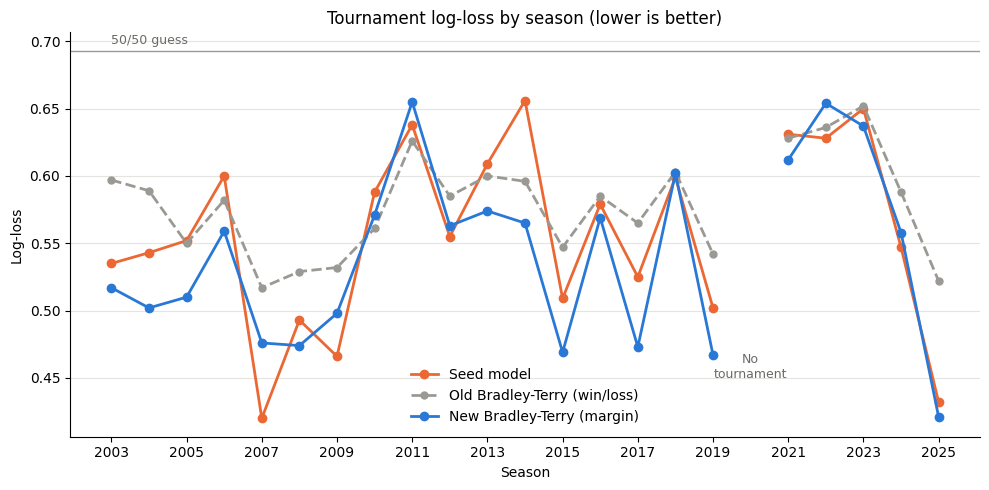

In [13]:
import matplotlib.pyplot as plt

plot_df = compare.set_index("Season").reindex(range(2003, 2026))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(plot_df.index, plot_df["Seed"], color="#eb6834", linewidth=2,
        marker="o", markersize=6, label="Seed model")
ax.plot(plot_df.index, plot_df["Old BT (win/loss)"], color="#9a9994", linewidth=2,
        linestyle="--", marker="o", markersize=5, label="Old Bradley-Terry (win/loss)")
ax.plot(plot_df.index, plot_df["New BT (margin)"], color="#2a78d6", linewidth=2,
        marker="o", markersize=6, label="New Bradley-Terry (margin)")

ax.axhline(0.693, color="#9a9994", linewidth=1)
ax.text(2003, 0.698, "50/50 guess", color="#6b6a66", fontsize=9)

ax.text(2020, 0.45, "No\ntournament", ha="center", color="#6b6a66", fontsize=9)

ax.set_title("Tournament log-loss by season (lower is better)")
ax.set_xlabel("Season")
ax.set_ylabel("Log-loss")
ax.set_xticks(range(2003, 2026, 2))
ax.grid(axis="y", color="#e5e4e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("results/logloss_all_three_models.png", dpi=200)
plt.show()

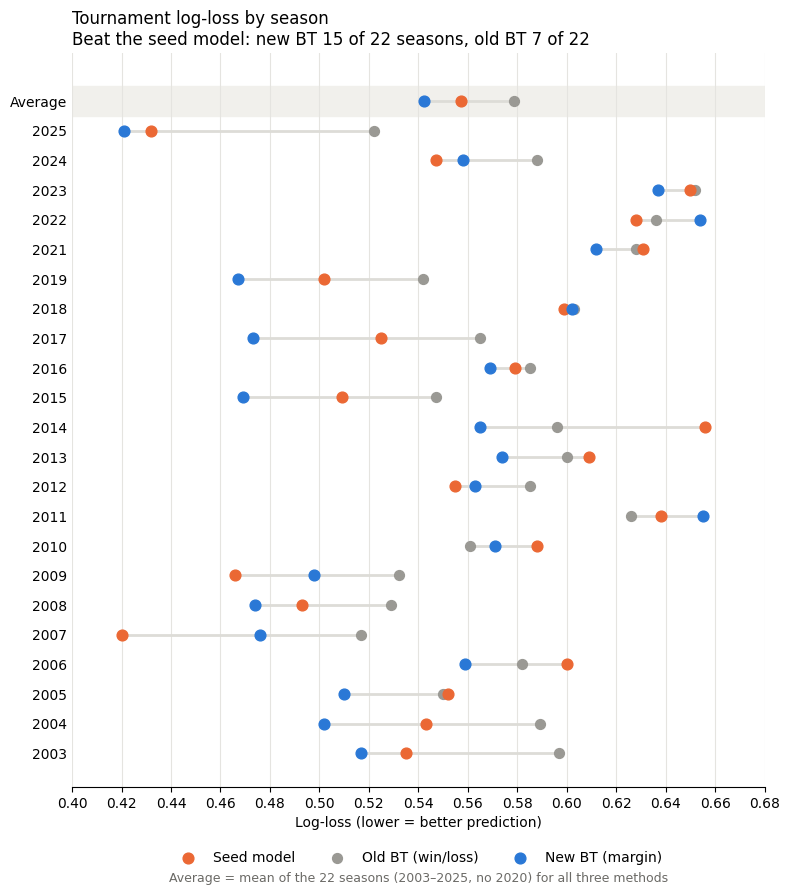

In [14]:


labels = list(compare["Season"].astype(str)) + ["Average"]
seed_vals = list(compare["Seed"]) + [compare["Seed"].mean()]
old_vals = list(compare["Old BT (win/loss)"]) + [compare["Old BT (win/loss)"].mean()]
new_vals = list(compare["New BT (margin)"]) + [compare["New BT (margin)"].mean()]

wins_old = (compare["Old BT (win/loss)"] < compare["Seed"]).sum()
wins_new = (compare["New BT (margin)"] < compare["Seed"]).sum()

fig, ax = plt.subplots(figsize=(8, 9))

for i in range(len(labels)):
    low = min(seed_vals[i], old_vals[i], new_vals[i])
    high = max(seed_vals[i], old_vals[i], new_vals[i])
    ax.plot([low, high], [i, i], color="#dddcd7", linewidth=2, zorder=1)
    ax.scatter(old_vals[i], i, color="#9a9994", s=50, zorder=2)
    ax.scatter(seed_vals[i], i, color="#eb6834", s=60, zorder=3)
    ax.scatter(new_vals[i], i, color="#2a78d6", s=60, zorder=4)


ax.scatter([], [], color="#eb6834", s=60, label="Seed model")
ax.scatter([], [], color="#9a9994", s=50, label="Old BT (win/loss)")
ax.scatter([], [], color="#2a78d6", s=60, label="New BT (margin)")


ax.axhspan(len(labels) - 1.5, len(labels) - 0.5, color="#f1f0ec", zorder=0)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

ax.set_xlim(0.40, 0.68)
ax.set_xticks(np.arange(0.40, 0.69, 0.02))
ax.set_xticklabels([f"{x:.2f}" for x in np.arange(0.40, 0.69, 0.02)])

ax.set_title(f"Tournament log-loss by season\n"
             f"Beat the seed model: new BT {wins_new} of {len(compare)} seasons, "
             f"old BT {wins_old} of {len(compare)}", loc="left")
ax.set_xlabel("Log-loss (lower = better prediction)")
ax.grid(axis="x", color="#e5e4e0")
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3)
ax.text(0.5, -0.13, "Average = mean of the 22 seasons (2003–2025, no 2020) for all three methods",
        transform=ax.transAxes, ha="center", fontsize=9, color="#6b6a66")

plt.tight_layout()
plt.savefig("results/logloss_dotplot_all_three.png", dpi=200, bbox_inches="tight")
plt.show()

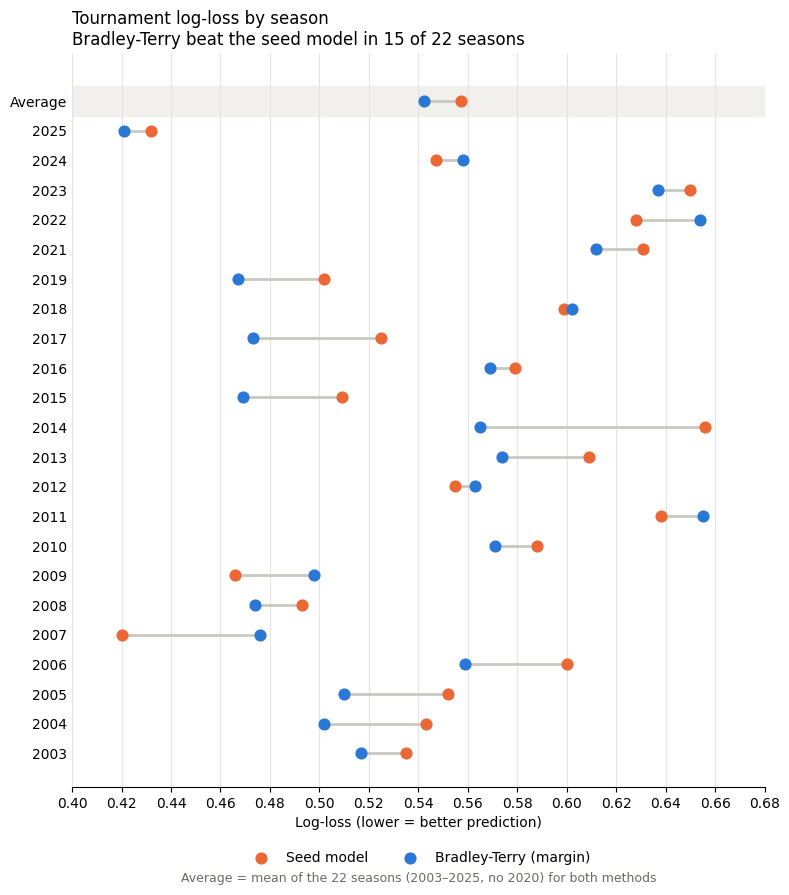

In [15]:


labels = list(compare["Season"].astype(str)) + ["Average"]
seed_vals = list(compare["Seed"]) + [compare["Seed"].mean()]
bt_vals = list(compare["New BT (margin)"]) + [compare["New BT (margin)"].mean()]
wins = (compare["New BT (margin)"] < compare["Seed"]).sum()

fig, ax = plt.subplots(figsize=(8, 9))

for i in range(len(labels)):
    ax.plot([seed_vals[i], bt_vals[i]], [i, i], color="#c9c8c3", linewidth=2, zorder=1)
    ax.scatter(seed_vals[i], i, color="#eb6834", s=60, zorder=2)
    ax.scatter(bt_vals[i], i, color="#2a78d6", s=60, zorder=2)

ax.scatter([], [], color="#eb6834", s=60, label="Seed model")
ax.scatter([], [], color="#2a78d6", s=60, label="Bradley-Terry (margin)")

ax.axhspan(len(labels) - 1.5, len(labels) - 0.5, color="#f1f0ec", zorder=0)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

ax.set_title(f"Tournament log-loss by season\nBradley-Terry beat the seed model in {wins} of {len(compare)} seasons", loc="left")
ax.set_xlabel("Log-loss (lower = better prediction)")
ax.grid(axis="x", color="#e5e4e0")
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0.40, 0.68)
ax.set_xticks(np.arange(0.40, 0.69, 0.02))
ax.set_xticklabels([f"{x:.2f}" for x in np.arange(0.40, 0.69, 0.02)])

ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
ax.text(0.5, -0.13, "Average = mean of the 22 seasons (2003–2025, no 2020) for both methods",
        transform=ax.transAxes, ha="center", fontsize=9, color="#6b6a66")

plt.tight_layout()
plt.savefig("results/bt_margin_vs_seed_dotplot.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
seasons = sorted(fits.keys())
draw_logloss = {}   

for season in seasons:
    theta_draws, sigma_draws, position = fits[season]

    seeds = df_seed[df_seed["Season"] == season]
    seed_str = dict(zip(seeds["TeamID"], seeds["Seed"]))
    tour = tour_all[tour_all["Season"] == season]

    winners = []
    losers = []
    for _, game in tour.iterrows():
        winner = game["WTeamID"]
        loser = game["LTeamID"]
        if len(seed_str[winner]) == 4 and len(seed_str[loser]) == 4:
            continue   # skip First Four
        winners.append(position[winner])
        losers.append(position[loser])

    # one row per draw, one column per game
    diff = theta_draws[:, winners] - theta_draws[:, losers]
    p = norm.cdf(diff / sigma_draws[:, None])

    # average across games, so each draw gets one log-loss
    draw_logloss[season] = -np.mean(np.log(p), axis=1)

ranges = pd.DataFrame({"Season": seasons,
                       "Low (2.5%)": [np.percentile(draw_logloss[s], 2.5) for s in seasons],
                       "Median": [np.median(draw_logloss[s]) for s in seasons],
                       "High (97.5%)": [np.percentile(draw_logloss[s], 97.5) for s in seasons]}).round(3)
ranges

,Season,Low (2.5%),Median,High (97.5%)
0,2003,0.486,0.534,0.585
1,2004,0.476,0.519,0.564
2,2005,0.483,0.527,0.574
3,2006,0.530,0.576,0.626
4,2007,0.451,0.490,0.530
5,2008,0.453,0.488,0.525
6,2009,0.473,0.512,0.555
7,2010,0.542,0.588,0.641
8,2011,0.618,0.676,0.737
9,2012,0.539,0.580,0.626


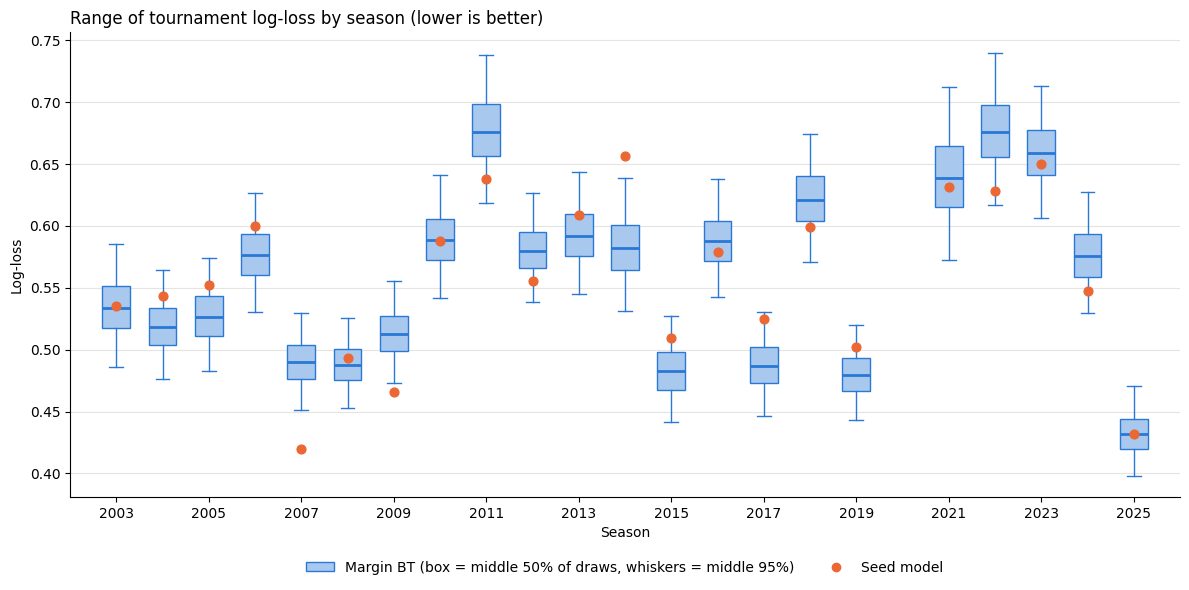

In [17]:

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot([draw_logloss[s] for s in seasons], positions=seasons, widths=0.6,
           whis=(2.5, 97.5), showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#a9c8ee", "edgecolor": "#2a78d6"},
           medianprops={"color": "#2a78d6", "linewidth": 2},
           whiskerprops={"color": "#2a78d6"}, capprops={"color": "#2a78d6"})

# the seed model has no posterior draws, so it gets one dot per year
seed_points = backtest.set_index("Season")["LogLoss_seed"]
ax.scatter(seasons, seed_points.loc[seasons], color="#eb6834", s=40, zorder=3)

ax.set_title("Range of tournament log-loss by season (lower is better)", loc="left")
ax.set_xlabel("Season")
ax.set_ylabel("Log-loss")
ax.set_xlim(2002, 2026)
ax.set_xticks(range(2003, 2026, 2))
ax.set_xticklabels(range(2003, 2026, 2))
ax.grid(axis="y", color="#e5e4e0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(handles=[Patch(facecolor="#a9c8ee", edgecolor="#2a78d6", label="Margin BT (box = middle 50% of draws, whiskers = middle 95%)"),
                   Line2D([], [], marker="o", color="none", markerfacecolor="#eb6834",
                          markeredgecolor="#eb6834", label="Seed model")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)

plt.tight_layout()
plt.savefig("results/bt_margin_logloss_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
recent = reg[(reg["Season"] >= 2003) & (reg["Season"] <= 2025) & (reg["Season"] != 2020)].copy()


recent["team1"] = np.minimum(recent["WTeamID"], recent["LTeamID"])
recent["win_margin"] = recent["WScore"] - recent["LScore"]
recent["margin"] = np.where(recent["WTeamID"] == recent["team1"],
                            recent["win_margin"], -recent["win_margin"])

print("Games:", len(recent))
print("Seasons:", recent["Season"].nunique())
print("Team1 margin mean:", round(recent["margin"].mean(), 2))
print("Team1 margin SD:", round(recent["margin"].std(), 2))
print("Average winning margin:", round(recent["win_margin"].mean(), 2))
print("Median winning margin:", recent["win_margin"].median())
print("Games decided by 5 or fewer:", round((recent["win_margin"] <= 5).mean() * 100, 1), "%")
print("Games decided by 20 or more:", round((recent["win_margin"] >= 20).mean() * 100, 1), "%")

Games: 113554
Seasons: 22
Team1 margin mean: -0.4
Team1 margin SD: 15.12
Average winning margin: 11.98
Median winning margin: 10.0
Games decided by 5 or fewer: 28.0 %
Games decided by 20 or more: 17.7 %


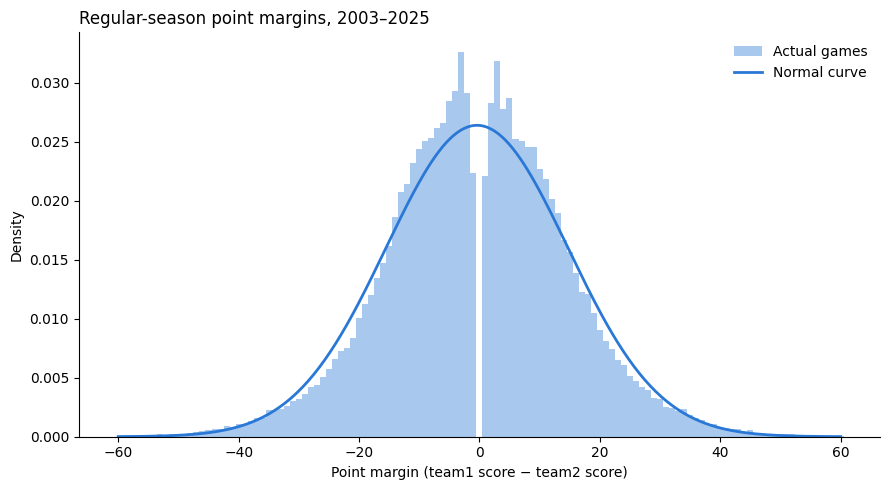

In [19]:


mean_margin = recent["margin"].mean()
sd_margin = recent["margin"].std()
x = np.linspace(-60, 60, 400)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(recent["margin"], bins=np.arange(-60.5, 61.5, 1), density=True,
        color="#a9c8ee", label="Actual games")
ax.plot(x, norm.pdf(x, mean_margin, sd_margin), color="#2a78d6", linewidth=2,
        label="Normal curve")

ax.set_title("Regular-season point margins, 2003–2025", loc="left")
ax.set_xlabel("Point margin (team1 score − team2 score)")
ax.set_ylabel("Density")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("results/exploration_margin_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

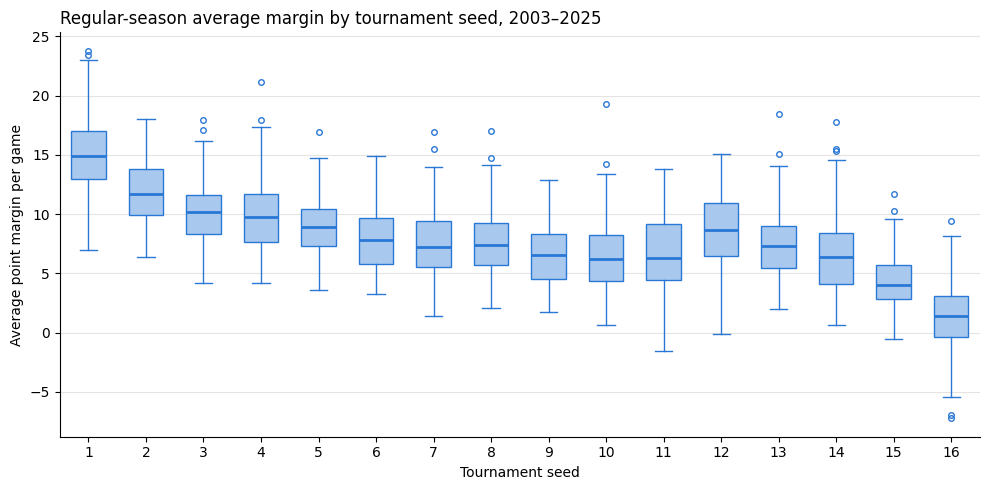

Correlation between seed and average margin: -0.634


In [20]:
wins = pd.DataFrame({"Season": recent["Season"], "TeamID": recent["WTeamID"],
                     "team_margin": recent["win_margin"]})
losses = pd.DataFrame({"Season": recent["Season"], "TeamID": recent["LTeamID"],
                       "team_margin": -recent["win_margin"]})

team_avg = pd.concat([wins, losses]).groupby(["Season", "TeamID"], as_index=False)["team_margin"].mean()

seed_table = df_seed.copy()
seed_table["SeedNum"] = seed_table["Seed"].str[1:3].astype(int)
team_avg = team_avg.merge(seed_table[["Season", "TeamID", "SeedNum"]], on=["Season", "TeamID"])

by_seed = [team_avg[team_avg["SeedNum"] == s]["team_margin"] for s in range(1, 17)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(by_seed, positions=range(1, 17), widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#a9c8ee", "edgecolor": "#2a78d6"},
           medianprops={"color": "#2a78d6", "linewidth": 2},
           whiskerprops={"color": "#2a78d6"}, capprops={"color": "#2a78d6"},
           flierprops={"markeredgecolor": "#2a78d6", "markersize": 4})

ax.set_title("Regular-season average margin by tournament seed, 2003–2025", loc="left")
ax.set_xlabel("Tournament seed")
ax.set_ylabel("Average point margin per game")
ax.grid(axis="y", color="#e5e4e0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("results/exploration_margin_by_seed.png", dpi=200, bbox_inches="tight")
plt.show()

print("Correlation between seed and average margin:",
      round(team_avg["SeedNum"].corr(team_avg["team_margin"]), 3))

In [21]:
diag_rows = []
resid_frames = []

for season in sorted(fits.keys()):
    games = reg[reg["Season"] == season].copy()
    games["team1"] = np.minimum(games["WTeamID"], games["LTeamID"])
    games["team2"] = np.maximum(games["WTeamID"], games["LTeamID"])
    games["outcome"] = (games["WTeamID"] == games["team1"]).astype(int)
    games["margin"] = np.where(games["outcome"] == 1,
                               games["WScore"] - games["LScore"],
                               games["LScore"] - games["WScore"])

    # team1's location, only used to check the residuals
    winner_home = games["WLoc"].map({"H": 1, "A": -1, "N": 0})
    games["loc"] = np.where(games["outcome"] == 1, winner_home, -winner_home)

    team_ids = sorted(set(games["team1"]) | set(games["team2"]))
    position = {team: i for i, team in enumerate(team_ids)}
    pos1 = games["team1"].map(position).values
    pos2 = games["team2"].map(position).values

    with pm.Model():
        theta = pm.ZeroSumNormal("theta", sigma=10, shape=len(team_ids))
        sigma = pm.HalfNormal("sigma", sigma=15)
        pm.Normal("margin", mu=theta[pos1] - theta[pos2], sigma=sigma,
                  observed=games["margin"].values)
        idata = pm.sample(draws=1000, tune=1000, chains=4,
                          random_seed=RANDOM_SEED, progressbar=False)

    summary = az.summary(idata, var_names=["theta", "sigma"])
    diag_rows.append({"Season": season,
                      "Max r_hat": summary["r_hat"].max(),
                      "Min ESS bulk": summary["ess_bulk"].min(),
                      "Min ESS tail": summary["ess_tail"].min(),
                      "Divergences": int(idata.sample_stats["diverging"].sum()),
                      "Sigma": round(float(idata.posterior["sigma"].mean()), 2)})

    theta_mean = idata.posterior["theta"].mean(dim=("chain", "draw")).values
    games["fitted"] = theta_mean[pos1] - theta_mean[pos2]
    games["resid"] = games["margin"] - games["fitted"]
    resid_frames.append(games[["Season", "loc", "fitted", "resid"]])

diagnostics = pd.DataFrame(diag_rows)
residuals = pd.concat(resid_frames)
diagnostics.to_csv("results/bt_margin_diagnostics.csv", index=False)
diagnostics

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 

,Season,Max r_hat,Min ESS bulk,Min ESS tail,Divergences,Sigma
0,2003,1.005171,4878.216331,2646.231292,0,11.02
1,2004,1.004643,5135.550057,2454.839483,0,10.99
2,2005,1.004317,5207.684830,2662.954516,0,10.97
3,2006,1.005457,5331.081198,2521.603983,0,10.97
4,2007,1.007146,5672.043337,2563.260651,0,10.93
5,2008,1.005916,5176.296308,2413.519252,0,11.04
6,2009,1.005815,5663.521018,2608.915102,0,10.82
7,2010,1.005720,5682.957857,2432.313327,0,10.65
8,2011,1.004891,5271.990286,2541.034325,0,10.67
9,2012,1.005390,5692.350741,2206.221539,0,10.61


Residual mean: -0.05
Residual SD: 10.529
Skewness: 0.006
Excess kurtosis: 0.28
     mean    std  count
loc                    
-1  -3.28  10.05  51331
 0   0.13  10.18  11821
 1   3.20  10.07  50402


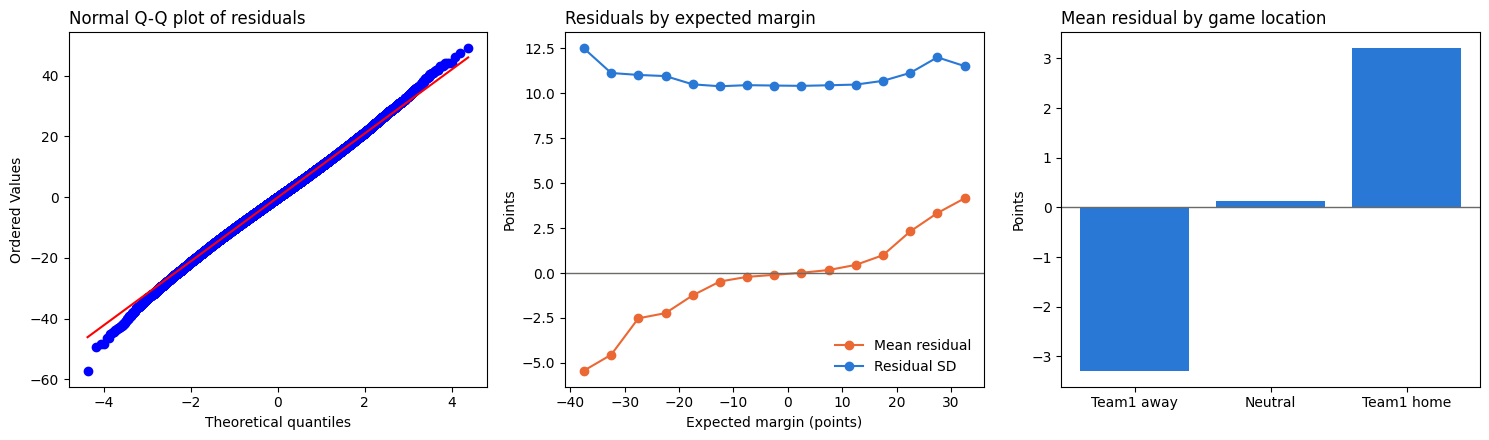

In [24]:
from scipy import stats

print("Residual mean:", round(residuals["resid"].mean(), 3))
print("Residual SD:", round(residuals["resid"].std(), 3))
print("Skewness:", round(residuals["resid"].skew(), 3))
print("Excess kurtosis:", round(residuals["resid"].kurt(), 3))
print(residuals.groupby("loc")["resid"].agg(["mean", "std", "count"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Are the residuals Normal?
stats.probplot(residuals["resid"], dist="norm", plot=axes[0])
axes[0].set_title("")
axes[0].set_title("Normal Q-Q plot of residuals", loc="left")

# 2. Are they centered on zero, with constant variance?
bins = pd.cut(residuals["fitted"], bins=np.arange(-50, 55, 5))
binned = residuals.groupby(bins, observed=True)["resid"].agg(["mean", "std", "count"])
binned = binned[binned["count"] >= 100]
centers = [interval.mid for interval in binned.index]

axes[1].plot(centers, binned["mean"], color="#eb6834", marker="o", label="Mean residual")
axes[1].plot(centers, binned["std"], color="#2a78d6", marker="o", label="Residual SD")
axes[1].axhline(0, color="#6b6a66", linewidth=1)
axes[1].set_title("Residuals by expected margin", loc="left")
axes[1].set_xlabel("Expected margin (points)")
axes[1].set_ylabel("Points")
axes[1].legend(frameon=False)

# 3. Did removing home court leave a pattern?
loc_means = residuals.groupby("loc")["resid"].mean()
axes[2].bar(["Team1 away", "Neutral", "Team1 home"],
            [loc_means[-1], loc_means[0], loc_means[1]], color="#2a78d6")
axes[2].axhline(0, color="#6b6a66", linewidth=1)
axes[2].set_title("Mean residual by game location", loc="left")
axes[2].set_ylabel("Points")

plt.tight_layout()
plt.savefig("results/diagnostics_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

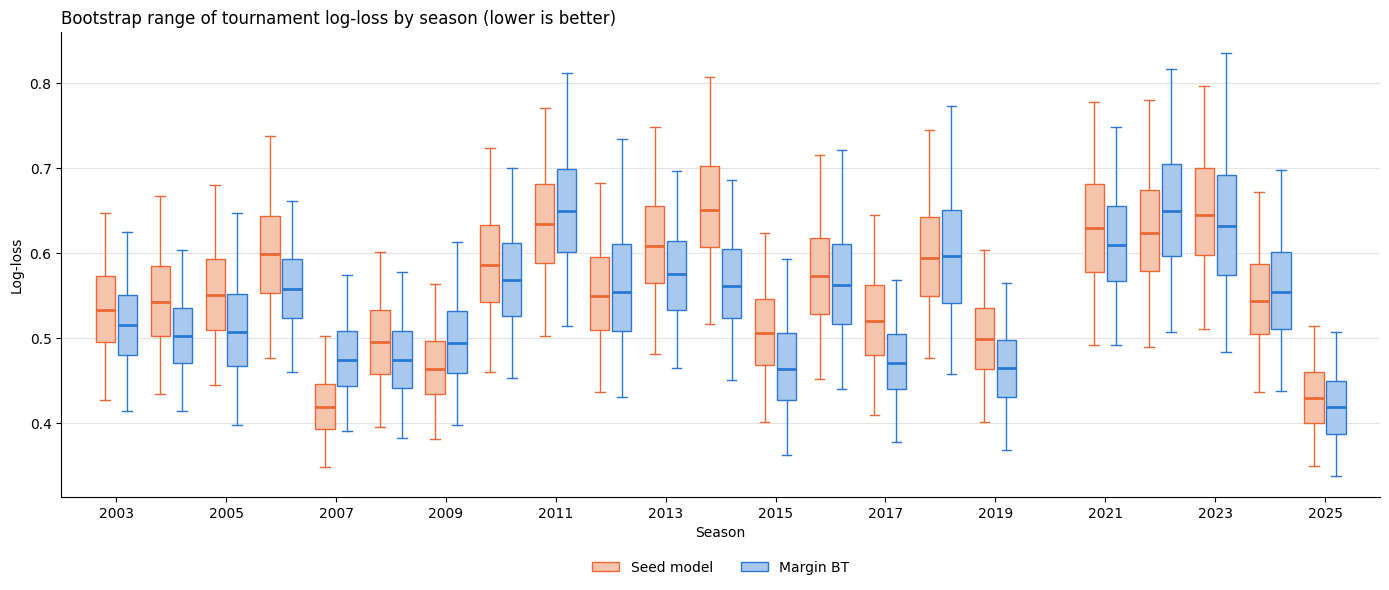

In [23]:
from matplotlib.patches import Patch

rng = np.random.default_rng(RANDOM_SEED)
boot_seed = {}
boot_bt = {}

for season in seasons:
    year = games_df[games_df["Season"] == season]
    p_seed_year = year["p_seed"].values
    p_bt_year = year["p_bt"].values
    n = len(year)

    seed_scores = []
    bt_scores = []
    for b in range(2000):
        picks = rng.integers(0, n, n)  
        seed_scores.append(-np.mean(np.log(p_seed_year[picks])))
        bt_scores.append(-np.mean(np.log(p_bt_year[picks])))

    boot_seed[season] = seed_scores
    boot_bt[season] = bt_scores

fig, ax = plt.subplots(figsize=(14, 6))

ax.boxplot([boot_seed[s] for s in seasons], positions=[s - 0.2 for s in seasons],
           widths=0.35, whis=(2.5, 97.5), showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#f6c4ad", "edgecolor": "#eb6834"},
           medianprops={"color": "#eb6834", "linewidth": 2},
           whiskerprops={"color": "#eb6834"}, capprops={"color": "#eb6834"})

ax.boxplot([boot_bt[s] for s in seasons], positions=[s + 0.2 for s in seasons],
           widths=0.35, whis=(2.5, 97.5), showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#a9c8ee", "edgecolor": "#2a78d6"},
           medianprops={"color": "#2a78d6", "linewidth": 2},
           whiskerprops={"color": "#2a78d6"}, capprops={"color": "#2a78d6"})

ax.set_title("Bootstrap range of tournament log-loss by season (lower is better)", loc="left")
ax.set_xlabel("Season")
ax.set_ylabel("Log-loss")
ax.set_xlim(2002, 2026)
ax.set_xticks(range(2003, 2026, 2))
ax.set_xticklabels(range(2003, 2026, 2))
ax.grid(axis="y", color="#e5e4e0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(handles=[Patch(facecolor="#f6c4ad", edgecolor="#eb6834", label="Seed model"),
                   Patch(facecolor="#a9c8ee", edgecolor="#2a78d6", label="Margin BT")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)

plt.tight_layout()
plt.savefig("results/logloss_bootstrap_both_models.png", dpi=200, bbox_inches="tight")
plt.show()